# Notebook 02: Baseline Models (LSTM, GRU)
## Graduation Thesis: CNN-BiLSTM-Attention Model for Electricity Load Forecasting in a Microgrid

**Baseline Models:**
1. LSTM (Long Short-Term Memory)
2. GRU (Gated Recurrent Unit)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, json, joblib, warnings
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from helpers import inverse_transform_target, calculate_metrics, plot_training_history, plot_predictions

warnings.filterwarnings('ignore')
tf.random.set_seed(42)
np.random.seed(42)

PROJECT_DIR = os.getcwd()
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')
os.makedirs(MODELS_DIR, exist_ok=True)

# Load data
data = np.load(os.path.join(DATA_DIR, 'processed_data.npz'))
X_train, y_train = data['X_train'], data['y_train']
X_val, y_val = data['X_val'], data['y_val']
X_test, y_test = data['X_test'], data['y_test']

with open(os.path.join(DATA_DIR, 'config.json')) as f:
    config = json.load(f)

scaler = joblib.load(os.path.join(DATA_DIR, 'scaler.pkl'))
TARGET_IDX = config['TARGET_IDX']
n_features = config['n_features']

print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')
print(f'Features: {n_features}')

X_train: (12115, 48, 37)
X_test: (2559, 48, 37)
Features: 37


## 1. LSTM Model

In [2]:
# Build LSTM
model_lstm = Sequential([
    LSTM(128, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(64, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_lstm.summary()

callbacks = [
    EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6)
]

history_lstm = model_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100, batch_size=32,
    callbacks=callbacks, verbose=1
)

model_lstm.save(os.path.join(MODELS_DIR, 'lstm_model.keras'))
print('LSTM model saved!')

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 48, 128)        │        84,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 136,513 (533.25 KB)

 Trainable params: 136,513 (533.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


... (6,724 outputs left out)


375/379 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 2.2955e-04


377/379 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 2.2958e-04


379/379 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - loss: 2.3659e-04 - val_loss: 2.2914e-04 - learning_rate: 1.5625e-05


LSTM model saved!


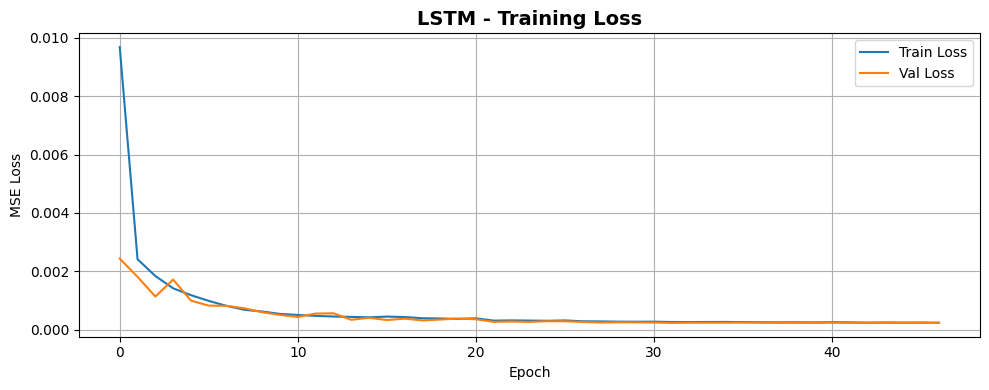


 1/80 ━━━━━━━━━━━━━━━━━━━━ 12s 159ms/step


 6/80 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step  


11/80 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


16/80 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


21/80 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


25/80 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

... (9 outputs left out)


76/80 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


=== LSTM Results ===
  MAE: 34.8784
  RMSE: 57.5928
  MAPE: 0.3638
  R2: 0.9880


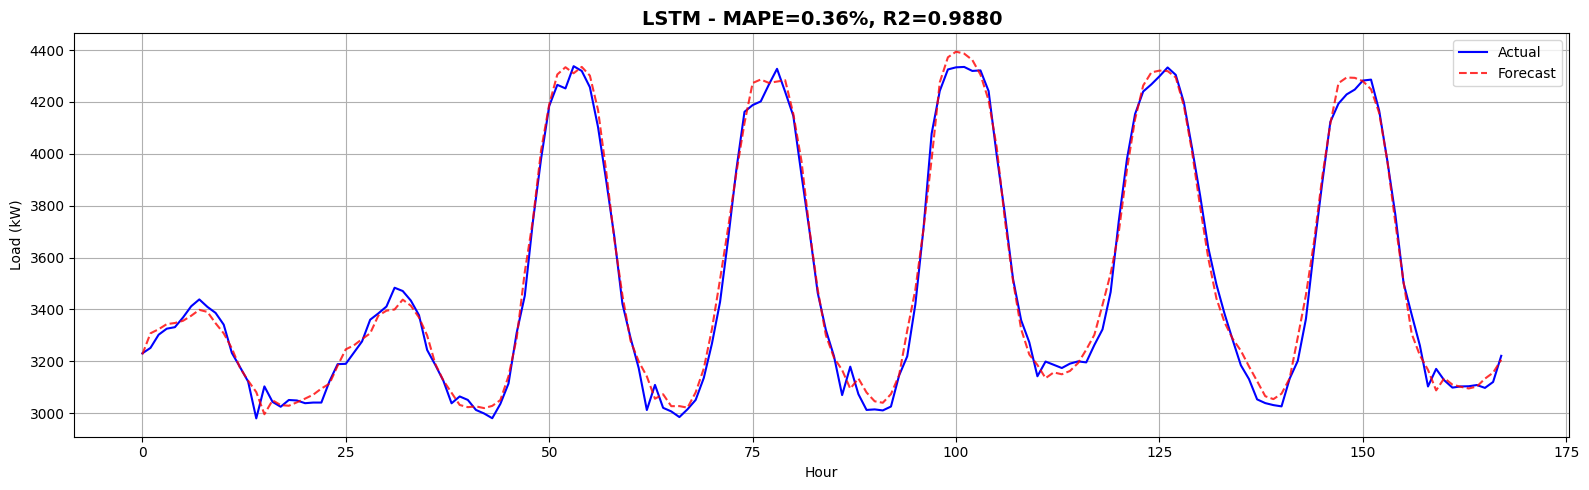

In [3]:
# Evaluate LSTM
plot_training_history(history_lstm, 'LSTM')

y_pred_lstm = model_lstm.predict(X_test).flatten()
y_true_real = inverse_transform_target(y_test, scaler, TARGET_IDX, n_features)
y_pred_lstm_real = inverse_transform_target(y_pred_lstm, scaler, TARGET_IDX, n_features)

metrics_lstm = calculate_metrics(y_true_real, y_pred_lstm_real)
print('=== LSTM Results ===')
for k, v in metrics_lstm.items():
    print(f'  {k}: {v:.4f}')

plot_predictions(y_true_real, y_pred_lstm_real, 'LSTM')

## 2. GRU Model

In [4]:
# Build GRU
model_gru = Sequential([
    GRU(128, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    GRU(64, return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model_gru.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_gru.summary()

history_gru = model_gru.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100, batch_size=32,
    callbacks=callbacks, verbose=1
)

model_gru.save(os.path.join(MODELS_DIR, 'gru_model.keras'))
print('GRU model saved!')

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 48, 128)        │        64,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 48, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103,489 (404.25 KB)

 Trainable params: 103,489 (404.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100


... (2,364 outputs left out)


375/379 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 4.4949e-04


377/379 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 4.4955e-04


379/379 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - loss: 4.6137e-04 - val_loss: 3.5987e-04 - learning_rate: 2.5000e-04


GRU model saved!


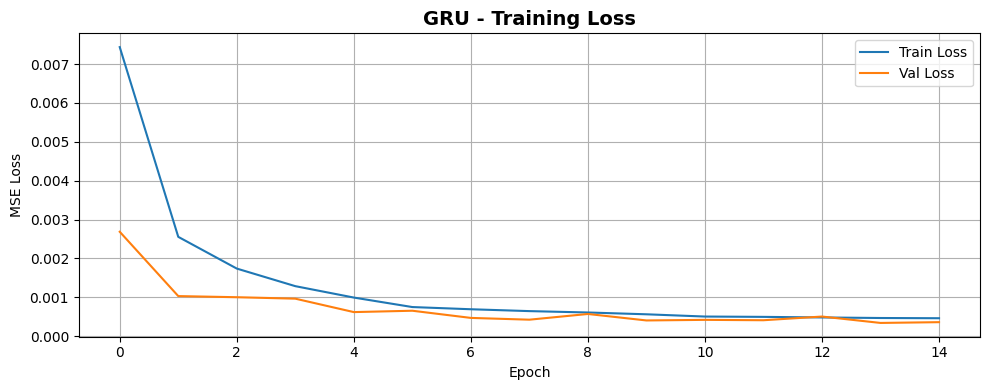


 1/80 ━━━━━━━━━━━━━━━━━━━━ 12s 163ms/step


 7/80 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step   


13/80 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


19/80 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


25/80 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


30/80 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

... (7 outputs left out)


75/80 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


=== GRU Results ===
  MAE: 132.4267
  RMSE: 160.4684
  MAPE: 3.4294
  R2: 0.9068


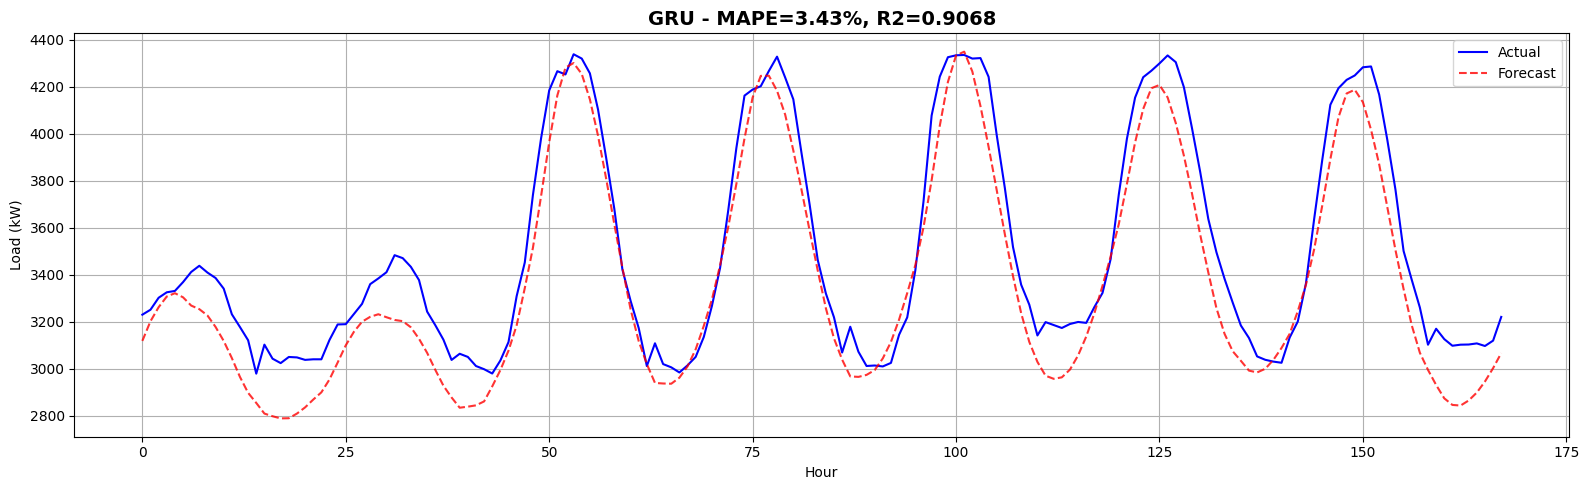

In [5]:
# Evaluate GRU
plot_training_history(history_gru, 'GRU')

y_pred_gru = model_gru.predict(X_test).flatten()
y_pred_gru_real = inverse_transform_target(y_pred_gru, scaler, TARGET_IDX, n_features)

metrics_gru = calculate_metrics(y_true_real, y_pred_gru_real)
print('=== GRU Results ===')
for k, v in metrics_gru.items():
    print(f'  {k}: {v:.4f}')

plot_predictions(y_true_real, y_pred_gru_real, 'GRU')

## 3. Summary of Baseline Model Results

             MAE        RMSE      MAPE        R2
LSTM   34.878381   57.592798  0.363839  0.988001
GRU   132.426656  160.468353  3.429379  0.906847


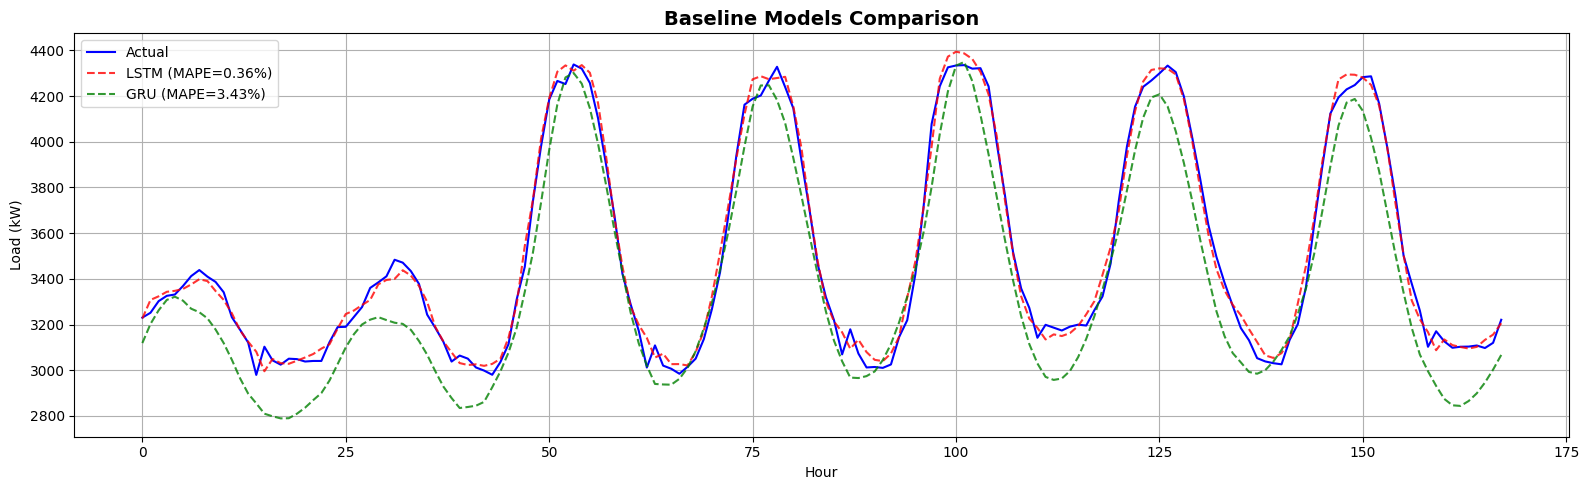


Notebook 02 hoàn tất! Tiếp theo: 03_Advanced_Models.ipynb


In [ ]:
# Save baseline results
results_df = pd.DataFrame([metrics_lstm, metrics_gru], index=['LSTM', 'GRU'])
results_df.to_csv(os.path.join(RESULTS_DIR, 'baseline_results.csv'))
print(results_df)

# Save predictions
np.savez_compressed(
    os.path.join(RESULTS_DIR, 'baseline_predictions.npz'),
    y_true=y_true_real,
    y_pred_lstm=y_pred_lstm_real,
    y_pred_gru=y_pred_gru_real
)

# Comparison plot
fig, ax = plt.subplots(figsize=(16, 5))
n = 168
ax.plot(range(n), y_true_real[:n], 'b-', label='Actual', linewidth=1.5)
ax.plot(range(n), y_pred_lstm_real[:n], 'r--', label=f'LSTM (MAPE={metrics_lstm["MAPE"]:.2f}%)', alpha=0.8)
ax.plot(range(n), y_pred_gru_real[:n], 'g--', label=f'GRU (MAPE={metrics_gru["MAPE"]:.2f}%)', alpha=0.8)
ax.set_title('Baseline Models Comparison', fontsize=14, fontweight='bold')
ax.set_xlabel('Hour')
ax.set_ylabel('Load (kW)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'baseline_comparison.png'), dpi=150)
plt.show()


print('\nNotebook 02 completed! Next: 03_Advanced_Models.ipynb')